In [1]:
import os
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect("../data/retail.duckdb", read_only=True)
os.makedirs("../images", exist_ok=True)

print(con.sql("SELECT COUNT(*) AS rows FROM clean_sales").df())

     rows
0  776577


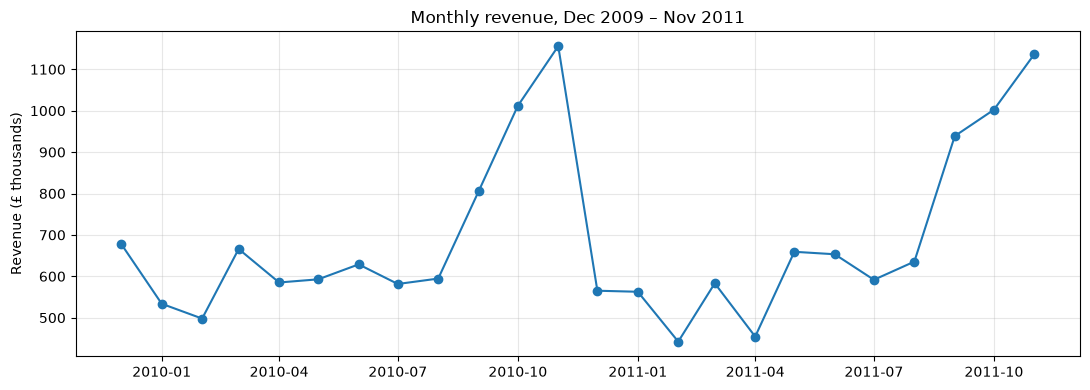

        month    revenue  customers
0  2009-12-01   677916.0        951
1  2010-01-01   533713.0        701
2  2010-02-01   497938.0        771
3  2010-03-01   665974.0       1051
4  2010-04-01   585127.0        939
5  2010-05-01   592734.0        965
6  2010-06-01   628809.0       1034
7  2010-07-01   581488.0        924
8  2010-08-01   594561.0        910
9  2010-09-01   805545.0       1136
10 2010-10-01  1011557.0       1492
11 2010-11-01  1155978.0       1606
12 2010-12-01   565200.0        884
13 2011-01-01   562683.0        739
14 2011-02-01   442294.0        757
15 2011-03-01   583144.0        973
16 2011-04-01   454441.0        853
17 2011-05-01   659242.0       1054
18 2011-06-01   653265.0        990
19 2011-07-01   591604.0        946
20 2011-08-01   635514.0        933
21 2011-09-01   938753.0       1259
22 2011-10-01  1002327.0       1361
23 2011-11-01  1136534.0       1660


In [2]:
monthly = con.sql("""
    SELECT date_trunc('month', invoicedate) AS month,
           ROUND(SUM(revenue), 0) AS revenue,
           COUNT(DISTINCT customer_id) AS customers
    FROM clean_sales
    WHERE invoicedate < '2011-12-01'   -- leave out partial Dec 2011
    GROUP BY month
    ORDER BY month
""").df()

plt.figure(figsize=(11, 4))
plt.plot(monthly["month"], monthly["revenue"] / 1000, marker="o")
plt.title("Monthly revenue, Dec 2009 – Nov 2011")
plt.ylabel("Revenue (£ thousands)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../images/monthly_revenue.png", dpi=150)
plt.show()

print(monthly.to_string())

In [4]:
import pandas as pd
[name for name, value in globals().items() if isinstance(value, pd.DataFrame)]


['monthly']

In [5]:
print(con.sql("DESCRIBE clean_sales").df()[["column_name", "column_type"]])

   column_name column_type
0      invoice     VARCHAR
1    stockcode     VARCHAR
2  description     VARCHAR
3     quantity      BIGINT
4  invoicedate   TIMESTAMP
5        price      DOUBLE
6  customer_id     INTEGER
7      country     VARCHAR
8      revenue      DOUBLE


In [6]:
check = con.sql("""
    SELECT
        COUNT(*)                                     AS total_rows,
        COUNT(*) FILTER (WHERE invoice LIKE 'C%')    AS cancelled_rows,
        COUNT(*) FILTER (WHERE quantity <= 0)        AS zero_or_negative_qty,
        COUNT(*) FILTER (WHERE price <= 0)           AS zero_or_negative_price,
        COUNT(*) FILTER (WHERE customer_id IS NULL)  AS missing_customer,
        MIN(invoicedate)                             AS first_date,
        MAX(invoicedate)                             AS last_date
    FROM clean_sales
""").df()
print(check.T)

                                          0
total_rows                           776577
cancelled_rows                            0
zero_or_negative_qty                      0
zero_or_negative_price                    0
missing_customer                          0
first_date              2009-12-01 07:45:00
last_date               2011-12-09 12:50:00


**Data check:** `clean_sales` has no cancelled invoices, returns, zero prices or missing customer IDs (776,577 rows). The data runs from 1 Dec 2009 to 9 Dec 2011, so December 2011 (only 9 days) is left out of the monthly analysis.

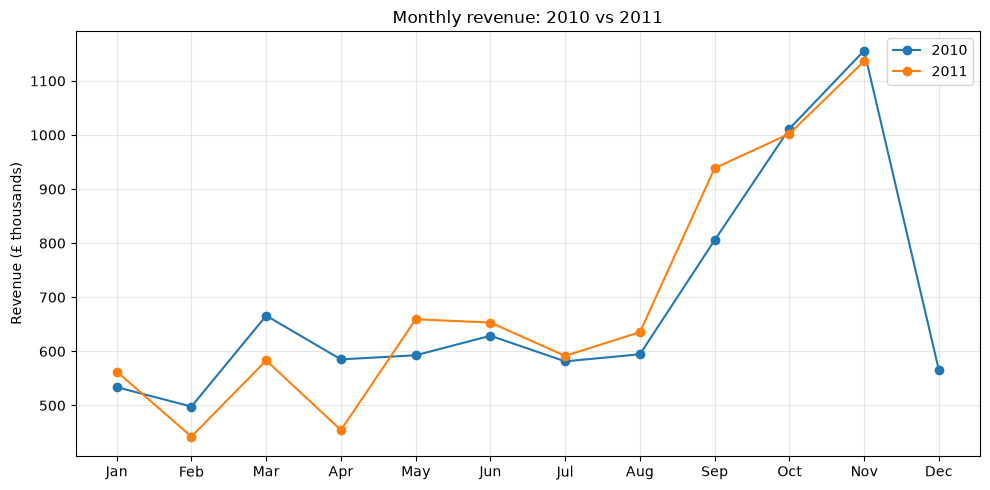

In [8]:
import pandas as pd

m = monthly.copy()
m["month"] = pd.to_datetime(m["month"])
m["year"] = m["month"].dt.year
m["month_num"] = m["month"].dt.month

plt.figure(figsize=(10, 5))
for year in [2010, 2011]:
    data = m[m["year"] == year]
    plt.plot(data["month_num"], data["revenue"] / 1000, marker="o", label=str(year))

plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.title("Monthly revenue: 2010 vs 2011")
plt.ylabel("Revenue (£ thousands)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../images/revenue_2010_vs_2011.png", dpi=150)
plt.show()


In [9]:
m























,month,revenue,customers,year,month_num
0,2009-12-01,677916.0,951,2009,12
1,2010-01-01,533713.0,701,2010,1
2,2010-02-01,497938.0,771,2010,2
3,2010-03-01,665974.0,1051,2010,3
4,2010-04-01,585127.0,939,2010,4
5,2010-05-01,592734.0,965,2010,5
6,2010-06-01,628809.0,1034,2010,6
7,2010-07-01,581488.0,924,2010,7
8,2010-08-01,594561.0,910,2010,8
9,2010-09-01,805545.0,1136,2010,9


## Findings

1. **Strong seasonality.** Revenue climbs from September and peaks in November in both years (£1.16M in Nov 2010, £1.14M in Nov 2011). September to November bring in about 36-37% of yearly revenue.
2. **No growth year on year.** Dec 2010 - Nov 2011 revenue was £8.23M, compared with £8.33M in Dec 2009 - Nov 2010 (-1.3%). A weak spring 2011 (April -22%) was balanced by a strong September (+16.5%).
3. **Peaks come from more customers, not bigger spending.** Active customers more than double from February to November 2011 (757 to 1,660), while revenue per customer stays between about £530 and £760 every month.
4. **December drops sharply.** Revenue halves from November to December 2010 (£1.16M to £0.57M), which suggests customers place their Christmas orders in October and November.